# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ x ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ x ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ x ] Visualize a few images from the dataset to understand what the data looks like.

In [1]:
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

2026-11-07 16:49:13.873040: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-07 16:49:13.873351: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-07 16:49:13.924371: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-07 16:49:15.457317: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To tur

In [2]:
# Inspect the shapes of the datasets
X_test.shape
X_train.shape

# Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical

#create dictionary to map integers back to class_names
class_dict = dict(zip(range(len(class_names)), class_names))

oh_train = to_categorical(y_train)
oh_test = to_categorical(y_test)



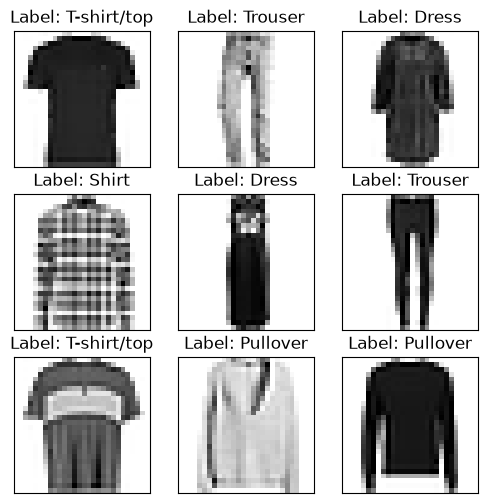

{0: 'T-shirt/top',
 1: 'Trouser',
 2: 'Pullover',
 3: 'Dress',
 4: 'Coat',
 5: 'Sandal',
 6: 'Shirt',
 7: 'Sneaker',
 8: 'Bag',
 9: 'Ankle boot'}

In [3]:
import matplotlib.pyplot as plt
import numpy as np
# Verify the data looks as expected
# Selecting 9 random indices
random_indices = np.random.choice(len(X_test), 9, replace=False)

# Creating a 3x3 grid plot
fig, axes = plt.subplots(3, 3, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[random_indices[i]], cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title(f"Label: {class_names[y_test[random_indices[i]]]}")

    # Removing axis labels
    ax.set_xticks([])
    ax.set_yticks([])

plt.show()
class_dict

Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

It looks as expected. The image quality is okay. definitely better than the digits dataset. Maybe some issues with "Sandal" in one of my runs when it is closer to a high heel, but there really isn't another class that it would fall into in class_names. 

# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ x ] Create a simple linear regression model using Keras.
- [ x ] Compile the model with an appropriate loss function and optimizer.
- [ x ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

The available loss functions in keras for classification are:
 - BinaryCrossentropy class
 - BinaryFocalCrossentropy class
 - CategoricalCrossentropy class
 - CategoricalFocalCrossentropy class
 - SparseCategoricalCrossentropy class
 - Poisson class
 - CTC class
 - KLDivergence class

In [4]:
#just to make sure that categories are relatively even and accuracy would be appropriate, let's check how often each label pops up in the training data
from collections import Counter
Counter(y_train)

#every class is evenly represented. Accuracy is interpretable and appropriate

Counter({np.uint8(9): 6000,
         np.uint8(0): 6000,
         np.uint8(3): 6000,
         np.uint8(2): 6000,
         np.uint8(7): 6000,
         np.uint8(5): 6000,
         np.uint8(1): 6000,
         np.uint8(6): 6000,
         np.uint8(4): 6000,
         np.uint8(8): 6000})

2026-11-07 16:49:17.637774: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - categorical_accuracy: 0.7734 - loss: 0.6902 - val_categorical_accuracy: 0.8242 - val_loss: 0.5203
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - categorical_accuracy: 0.8325 - loss: 0.4966 - val_categorical_accuracy: 0.8364 - val_loss: 0.4776
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - categorical_accuracy: 0.8439 - loss: 0.4612 - val_categorical_accuracy: 0.8422 - val_loss: 0.4561
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - categorical_accuracy: 0.8487 - loss: 0.4429 - val_categorical_accuracy: 0.8520 - val_loss: 0.4425
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - categorical_accuracy: 0.8530 - loss: 0.4296 - val_categorical_accuracy: 0.8440 - val_loss: 0.4490
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - categorical_accuracy: 0.8558 - loss: 0.4203 - val_categorical_accuracy: 0.8528 - val_loss: 0.4261
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - categorical_accuracy: 0.8589 - los

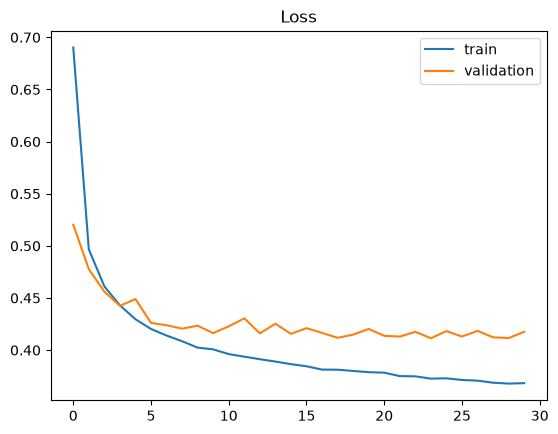

In [5]:
from keras import Input
from keras.models import Sequential
from keras.layers import Dense, Flatten

# Create a simple linear regression model
model = Sequential([
    Input(X_train[0].shape), #use an image from the training data to define the shape
    Flatten(), #collapse two-dimensional array to a one-dimensional vector
    Dense(len(class_names), activation = "softmax") #the output should be a vector for one of each class that is then converted to probability like values with softmax
    ]
)

# You can use `model.add(<layer>)` to add layers to the model
## A linear regression shouldn't need extra layers

# Compile the model using `model.compile()`
model.compile(
    optimizer = "adam", #adam just seems like a go-to optimizer for first passes
    loss = "categorical_crossentropy", #we're providing labels as one-hot encodings and this is a classificaiton problem
    metrics = ["categorical_accuracy"]
)

# Train the model with `model.fit()`
history = model.fit(
    X_train,
    oh_train,
    epochs = 30,
    batch_size = 64,
    validation_split = 0.2 
)

#plot training and validation loss just to make sure we're not over-fitting and if we don't need to run 100 epochs
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.legend(loc='best')
plt.title('Loss');
#the validation and training losses both seem to plateau very early on and validation loss increases a bit after the elbow

# Evaluate the model with `model.evaluate()`
test_loss, test_accuracy = model.evaluate(
    X_test,
    oh_test
)

print(f"Test loss:  {test_loss:.3f}")
print(f"Test accuracy: ' {test_accuracy:.3f}")

Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

The baseline model has an accuracy of ~85%. I honestly think that's better than I expected for a classification with just a linear regression. I think the performance might be at this level because the MNIST dataset must be highly standardized in the sense that images are all the same size, items are all centered, etc. So, broad differences between classes are good enough for distinguishing between classes with such standardized data.

# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ x ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ x ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ x ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

Epoch 1/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - categorical_accuracy: 0.8454 - loss: 0.4421 - val_categorical_accuracy: 0.8792 - val_loss: 0.3401
Epoch 2/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - categorical_accuracy: 0.8948 - loss: 0.2908 - val_categorical_accuracy: 0.8892 - val_loss: 0.3040
Epoch 3/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - categorical_accuracy: 0.9095 - loss: 0.2468 - val_categorical_accuracy: 0.8967 - val_loss: 0.2914
Epoch 4/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - categorical_accuracy: 0.9226 - loss: 0.2140 - val_categorical_accuracy: 0.8981 - val_loss: 0.2904
Epoch 5/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - categorical_accuracy: 0.9313 - loss: 0.1916 - val_categorical_accuracy: 0.9032 - val_loss: 0.2791
Epoch 6/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - categorical_accuracy: 0.9385 - loss: 0.1686 - val_categorical_accuracy: 0.8986 - val_loss: 0.2949
Epoch 7/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - categorical_accuracy: 0.9459 - los

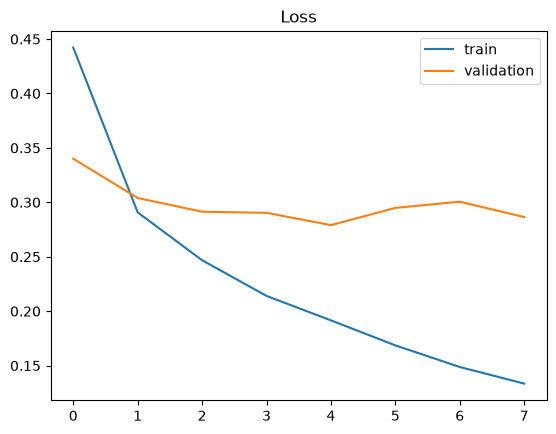

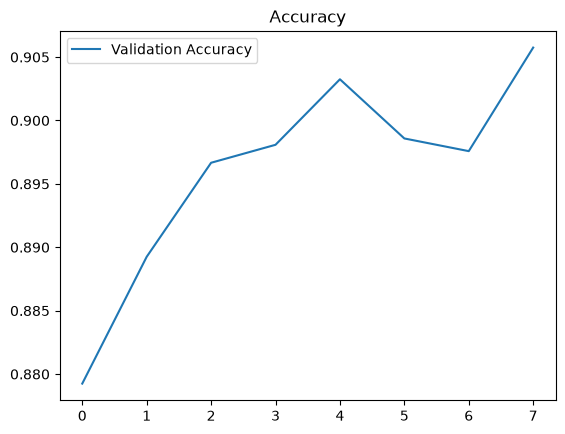

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - categorical_accuracy: 0.8981 - loss: 0.3110
Test loss:  0.311
Test accuracy: ' 0.898


In [6]:
from keras.layers import Conv2D
from keras.layers import MaxPool2D

# Reshape the data to include the channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

input_shape = X_train[0].shape
neuron_count = 32

# Create a simple CNN model
model = Sequential([
    Input(input_shape),

    #Convolutional layer
    Conv2D(neuron_count, (3,3), activation = "relu"), #Based on my research, 32 neurons and a (3,3) pixel search is good enough and efficient enough to identify broad patterns like edges and shapes

    #making the decision. So, we need to convert the matrix from a 2-d array to a one-dimensional vector. Use all the neurons and then produce the probability-like values via softmax
    Flatten(),
    Dense(neuron_count, activation = "relu"),

    Dense(len(class_names), activation = "softmax"),
])

#compile model
model.compile(
    optimizer = "adam", #adam just seems like a go-to optimizer for first passes
    loss = "categorical_crossentropy", #we're providing labels as one-hot encodings and this is a classificaiton problem
    metrics = ["categorical_accuracy"]
)

# Train the model
history = model.fit(
    X_train,
    oh_train,
    epochs = 8,
    batch_size = 64,
    validation_split = 0.2 
)

#plot training and validation loss just to make sure we're not over-fitting
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.legend(loc='best')
plt.title('Loss')
plt.show()
#overfitting, happens pretty early. We can stop at ~8 epochs

plt.plot(history.history['val_categorical_accuracy'], label='Validation Accuracy')
plt.legend(loc='best')
plt.title('Accuracy')
plt.show()

# Evaluate the model
test_loss, test_accuracy = model.evaluate(
    X_test,
    oh_test
)

print(f"Test loss:  {test_loss:.3f}")
print(f"Test accuracy: ' {test_accuracy:.3f}")

Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

Yes. It improved accuracy by an absolute increase of ~5-6%. I think the convolutional network is able to take into account more information like 2-d relationships that would be hard to tell from a one-dimensional array which provides information about shape and edges.

# 3. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ x ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ x ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ x ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ x ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.

In [7]:
# A. Test Hyperparameters
#I think playing around with more layers would be useful.

epoch_stop = 7
#### One extra layer ####
model_2 = Sequential([
    Input(input_shape),

    #Convolutional layer
    Conv2D(neuron_count, (3,3), activation = "relu"), #Based on my research, 32 neurons and a (3,3) pixel search is good enough and efficient enough to identify broad patterns like edges and shapes
    MaxPool2D((2, 2)), #This was recommended in my research to downsample the image and reduce computational cost. Also, it is supposed to help with changes in position.

    Conv2D(neuron_count * 2, (3,3), activation = "relu"), #Apparently, when using Max-Pool, it is recommended to increase the number of neurons to counteract some of the consequences of data loss from the down-sampling

    #making the decision. So, we need to convert the matrix from a 2-d array to a one-dimensional vector. Use all the neurons and then produce the probability-like values via softmax
    Flatten(),
    Dense(neuron_count * 2, activation = "relu"),

    Dense(len(class_names), activation = "softmax"),
])

#compile model
model_2.compile(
    optimizer = "adam", #adam just seems like a go-to optimizer for first passes
    loss = "categorical_crossentropy", #we're providing labels as one-hot encodings and this is a classificaiton problem
    metrics = ["categorical_accuracy"]
)

# Train the model
history_2 = model_2.fit(
    X_train,
    oh_train,
    epochs = epoch_stop,
    batch_size = 64,
    validation_split = 0.2 
)

#### Two extra layers ####
model_3 = Sequential([
    Input(input_shape),

    #Convolutional layer
    Conv2D(neuron_count, (3,3), activation = "relu"), #Based on my research, 32 neurons and a (3,3) pixel search is good enough and efficient enough to identify broad patterns like edges and shapes
    MaxPool2D((2, 2)), #This was recommended in my research to downsample the image and reduce computational cost. Also, it is supposed to help with changes in position.

    Conv2D(neuron_count * 2, (3,3), activation = "relu"),
    MaxPool2D((2, 2)),

    Conv2D(neuron_count * 2, (3,3), activation = "relu"),

    #making the decision. So, we need to convert the matrix from a 2-d array to a one-dimensional vector. Use all the neurons and then produce the probability-like values via softmax
    Flatten(),
    Dense(neuron_count * 2, activation = "relu"),

    Dense(len(class_names), activation = "softmax"),
])

#compile model
model_3.compile(
    optimizer = "adam", #adam just seems like a go-to optimizer for first passes
    loss = "categorical_crossentropy", #we're providing labels as one-hot encodings and this is a classificaiton problem
    metrics = ["categorical_accuracy"]
)

# Train the model
history_3 = model_3.fit(
    X_train,
    oh_train,
    epochs = epoch_stop,
    batch_size = 64,
    validation_split = 0.2 
)


Epoch 1/7
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - categorical_accuracy: 0.8374 - loss: 0.4553 - val_categorical_accuracy: 0.8685 - val_loss: 0.3628
Epoch 2/7
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - categorical_accuracy: 0.8948 - loss: 0.2929 - val_categorical_accuracy: 0.9030 - val_loss: 0.2679
Epoch 3/7
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - categorical_accuracy: 0.9122 - loss: 0.2434 - val_categorical_accuracy: 0.9078 - val_loss: 0.2577
Epoch 4/7
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - categorical_accuracy: 0.9221 - loss: 0.2096 - val_categorical_accuracy: 0.9091 - val_loss: 0.2556
Epoch 5/7
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - categorical_accuracy: 0.9355 - loss: 0.1798 - val_categorical_accuracy: 0.9160 - val_loss: 0.2353
Epoch 6/7
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - categorical_accuracy: 0.9430 - loss: 0.1551 - val_categorical_accuracy: 0.9195 - val_loss: 0.2371
Epoch 7/7
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - categorical_accuracy: 0.951

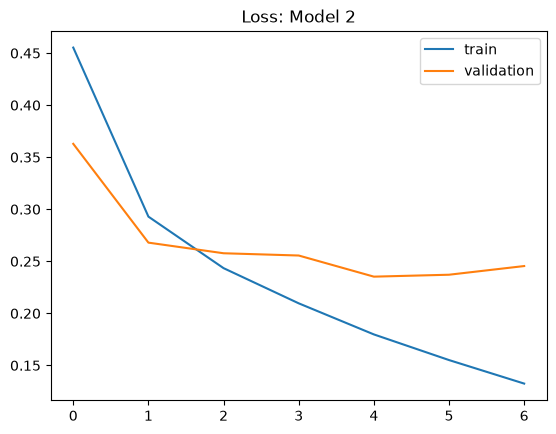

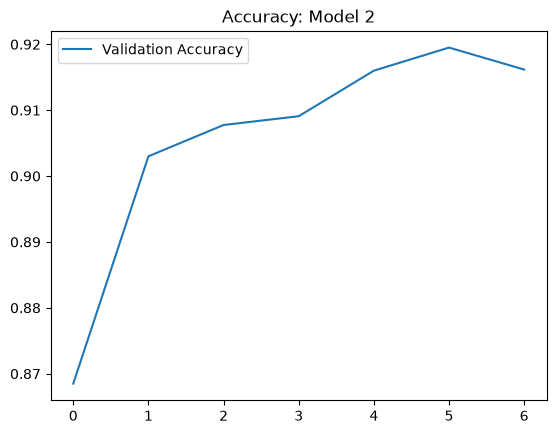

In [8]:
#plot training and validation loss just to make sure we're not over-fitting
plt.plot(history_2.history['loss'], label='train')
plt.plot(history_2.history['val_loss'], label='validation')
plt.legend(loc='best')
plt.title('Loss: Model 2')
plt.show()

plt.plot(history_2.history['val_categorical_accuracy'], label='Validation Accuracy')
plt.legend(loc='best')
plt.title('Accuracy: Model 2')
plt.show()

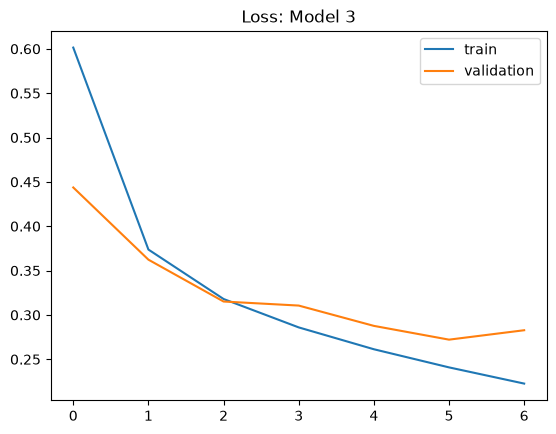

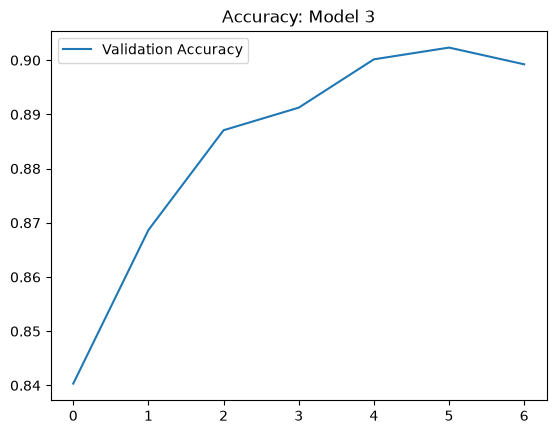

In [9]:
plt.plot(history_3.history['loss'], label='train')
plt.plot(history_3.history['val_loss'], label='validation')
plt.legend(loc='best')
plt.title('Loss: Model 3')
plt.show()

plt.plot(history_3.history['val_categorical_accuracy'], label='Validation Accuracy')
plt.legend(loc='best')
plt.title('Accuracy: Model 3')
plt.show()

Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - categorical_accuracy: 0.7848 - loss: 0.6196 - val_categorical_accuracy: 0.8703 - val_loss: 0.3625
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - categorical_accuracy: 0.8511 - loss: 0.4287 - val_categorical_accuracy: 0.8824 - val_loss: 0.3229
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - categorical_accuracy: 0.8634 - loss: 0.3784 - val_categorical_accuracy: 0.8876 - val_loss: 0.3055
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - categorical_accuracy: 0.8743 - loss: 0.3509 - val_categorical_accuracy: 0.8918 - val_loss: 0.2957
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - categorical_accuracy: 0.8826 - loss: 0.3271 - val_categorical_accuracy: 0.8943 - val_loss: 0.2919
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - categorical_accuracy: 0.8859 - loss: 0.3066 - val_categorical_accuracy: 0.8924 - val_loss: 0.3004
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - categorical_accuracy

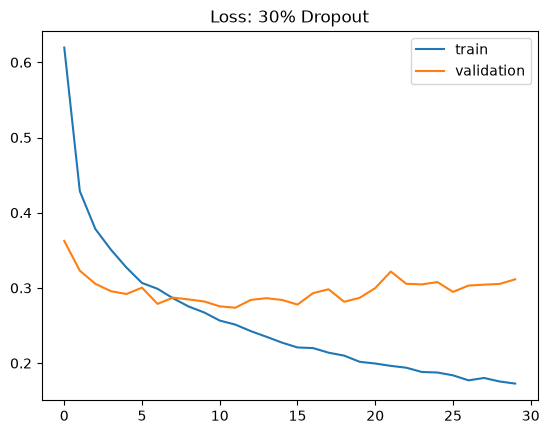

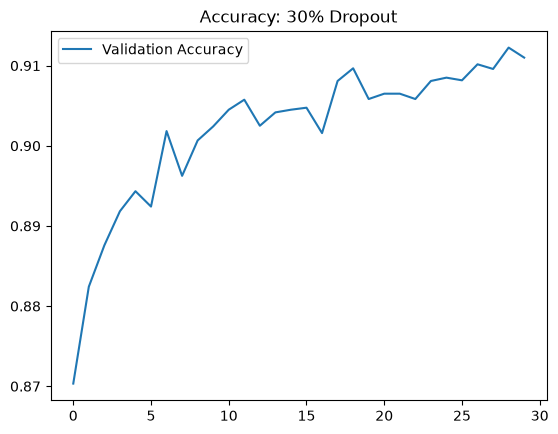

In [10]:
# B. Test presence or absence of regularization
#There is a tendency for overfitting very early on. Perhaps using drop-out may be useful.
#Only adding one extra layer performed better. Let's include drop-out in that model after each major layer grouping (code chunk after this one)

from keras.layers import Dropout

epoch_stop = 30
dr = 0.3

### The original, simple CNN with dropout
model_dr = Sequential([
    Input(input_shape),

    #Convolutional layer
    Conv2D(neuron_count, (3,3), activation = "relu"), #Based on my research, 32 neurons and a (3,3) pixel search is good enough and efficient enough to identify broad patterns like edges and shapes

    Dropout(dr),

    #making the decision. So, we need to convert the matrix from a 2-d array to a one-dimensional vector. Use all the neurons and then produce the probability-like values via softmax
    Flatten(),
    Dense(neuron_count, activation = "relu"),

    Dropout(dr),

    Dense(len(class_names), activation = "softmax"),
])

model_dr.compile(
    optimizer = "adam", #adam just seems like a go-to optimizer for first passes
    loss = "categorical_crossentropy", #we're providing labels as one-hot encodings and this is a classificaiton problem
    metrics = ["categorical_accuracy"]
)

history_dr = model_dr.fit(
    X_train,
    oh_train,
    epochs = epoch_stop,
    batch_size = 64,
    validation_split = 0.2 
)

#plot training and validation loss just to make sure we're not over-fitting
plt.plot(history_dr.history['loss'], label='train')
plt.plot(history_dr.history['val_loss'], label='validation')
plt.legend(loc='best')
plt.title('Loss: 30% Dropout')
plt.show()

plt.plot(history_dr.history['val_categorical_accuracy'], label='Validation Accuracy')
plt.legend(loc='best')
plt.title('Accuracy: 30% Dropout')
plt.show()

Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - categorical_accuracy: 0.7808 - loss: 0.6076 - val_categorical_accuracy: 0.8577 - val_loss: 0.4017
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - categorical_accuracy: 0.8537 - loss: 0.4103 - val_categorical_accuracy: 0.8852 - val_loss: 0.3176
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - categorical_accuracy: 0.8739 - loss: 0.3509 - val_categorical_accuracy: 0.8957 - val_loss: 0.2884
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - categorical_accuracy: 0.8848 - loss: 0.3204 - val_categorical_accuracy: 0.9024 - val_loss: 0.2643
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - categorical_accuracy: 0.8939 - loss: 0.2909 - val_categorical_accuracy: 0.9032 - val_loss: 0.2646
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - categorical_accuracy: 0.8980 - loss: 0.2786 - val_categorical_accuracy: 0.9141 - val_loss: 0.2387
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - categorical_accuracy

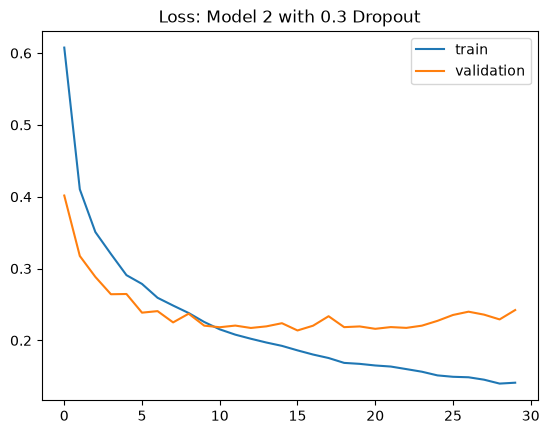

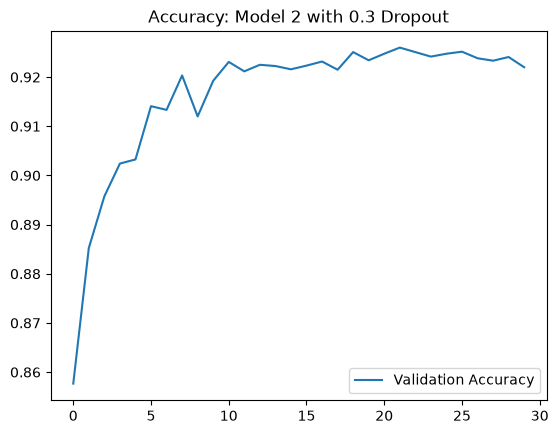

In [11]:
### The CNN model with one extra layer but including dropout
model_2_dr = Sequential([
    Input(input_shape),

    #Convolutional layer
    Conv2D(neuron_count, (3,3), activation = "relu"), #Based on my research, 32 neurons and a (3,3) pixel search is good enough and efficient enough to identify broad patterns like edges and shapes
    MaxPool2D((2, 2)), #This was recommended in my research to downsample the image and reduce computational cost. Also, it is supposed to help with changes in position.

    Dropout(dr),

    Conv2D(neuron_count * 2, (3,3), activation = "relu"), #Apparently, when using Max-Pool, it is recommended to increase the number of neurons to counteract some of the consequences of data loss from the down-sampling

    Dropout(dr),

    #making the decision. So, we need to convert the matrix from a 2-d array to a one-dimensional vector. Use all the neurons and then produce the probability-like values via softmax
    Flatten(),
    Dense(neuron_count * 2, activation = "relu"),

    Dropout(dr),

    Dense(len(class_names), activation = "softmax"),
])

#compile model
model_2_dr.compile(
    optimizer = "adam", #adam just seems like a go-to optimizer for first passes
    loss = "categorical_crossentropy", #we're providing labels as one-hot encodings and this is a classificaiton problem
    metrics = ["categorical_accuracy"]
)

# Train the model
history_2_dr = model_2_dr.fit(
    X_train,
    oh_train,
    epochs = epoch_stop,
    batch_size = 64,
    validation_split = 0.2 
)

plt.plot(history_2_dr.history['loss'], label='train')
plt.plot(history_2_dr.history['val_loss'], label='validation')
plt.legend(loc='best')
plt.title('Loss: Model 2 with 0.3 Dropout')
plt.show()

plt.plot(history_2_dr.history['val_categorical_accuracy'], label='Validation Accuracy')
plt.legend(loc='best')
plt.title('Accuracy: Model 2 with 0.3 Dropout')
plt.show()


Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

Adding one extra CNN layer with 30% drop-out marginally improved the model from the baseline regression by about 7% and by about 1-2% from the simple CNN. I think the extra layer allowed the network to identify more complex relationships and the drop-out (I had tested 0.1, 0.2, and 0.3) of 30% helped limit overfitting the model in the validation tests. So, overall, adding an extra CNN layer and dropping 30% of neurons at each major grouping in the neural network worked best.

# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ x ] Compile the final model with the best hyperparameters and regularization techniques.
- [ x ] Train the final model on the training set and evaluate it on the test set.
- [ x ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

In [12]:
# This is model_2_dr which I compiled and trained above.

#Evaluate against test data
test_loss, test_accuracy = model_2_dr.evaluate(
    X_test,
    oh_test
)

print(f"Test loss:  {test_loss:.3f}")
print(f"Test accuracy: ' {test_accuracy:.3f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - categorical_accuracy: 0.9179 - loss: 0.2650
Test loss:  0.265
Test accuracy: ' 0.918


Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

The final model performs about 5% in absolute terms better than the baseline model and about 1-2% better than the simple CNN. If I had time, I think I would try other optimization techniques or alternative learning rates just to make sure that my model is not falling into the same local minimum.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 26/10/2025`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.